# 04 — ResNet-50 transfer learning

Backbone: torchvision ResNet-50, **IMAGENET1K_V2**.
Head: `Linear(2048, 3)`. Protocol: freeze backbone → train head (`lr=1e-3`) → unfreeze `layer4` (`lr=1e-4`).
Same 224×224 ImageNet normalisation as Part 1. Numbers come from the saved experiment JSON.


In [1]:
from pathlib import Path
import json
from IPython.display import Image, display

from ml.engine.experiment_log import load_experiment_record
from ml.models import ResNet50Classifier

ROOT = Path.cwd() if (Path.cwd() / "reports").exists() else Path.cwd().parent
rec = load_experiment_record(ROOT / "reports" / "experiments", "resnet50")
print("experiment_id:", rec["experiment_id"])
print("pretrained:", ResNet50Classifier.pretrained_weights)
print("finetuned:", rec["finetuned"], "epochs:", [(h["phase"], h["epoch"]) for h in rec["history"]])
print("batch_size:", rec["batch_size"], "lr:", rec["learning_rate"], "ft lr:", rec["epochs_configured"].get("finetune_lr"))
print("seconds:", round(rec["training_seconds"], 1))


experiment_id: resnet50_20260918T041051Z
pretrained: IMAGENET1K_V2
finetuned: True epochs: [('head', 1), ('head', 2), ('head', 3), ('head', 4), ('head', 5), ('finetune', 6), ('finetune', 7), ('finetune', 8), ('finetune', 9)]
batch_size: 16 lr: 0.001 ft lr: 0.0001
seconds: 1203.6


VAL  acc=0.7805  macro-F1=0.6463  mild F1=0.3172 rec=0.3030
TEST acc=0.8070  macro-F1=0.6447
{
  "little_or_none": {
    "precision": 0.8686949559647719,
    "recall": 0.9029126213592233,
    "f1": 0.8854733405875952,
    "support": 3605
  },
  "mild": {
    "precision": 0.3328050713153724,
    "recall": 0.30303030303030304,
    "f1": 0.31722054380664655,
    "support": 693
  },
  "severe": {
    "precision": 0.7531428571428571,
    "recall": 0.7202185792349727,
    "f1": 0.7363128491620111,
    "support": 1830
  }
}


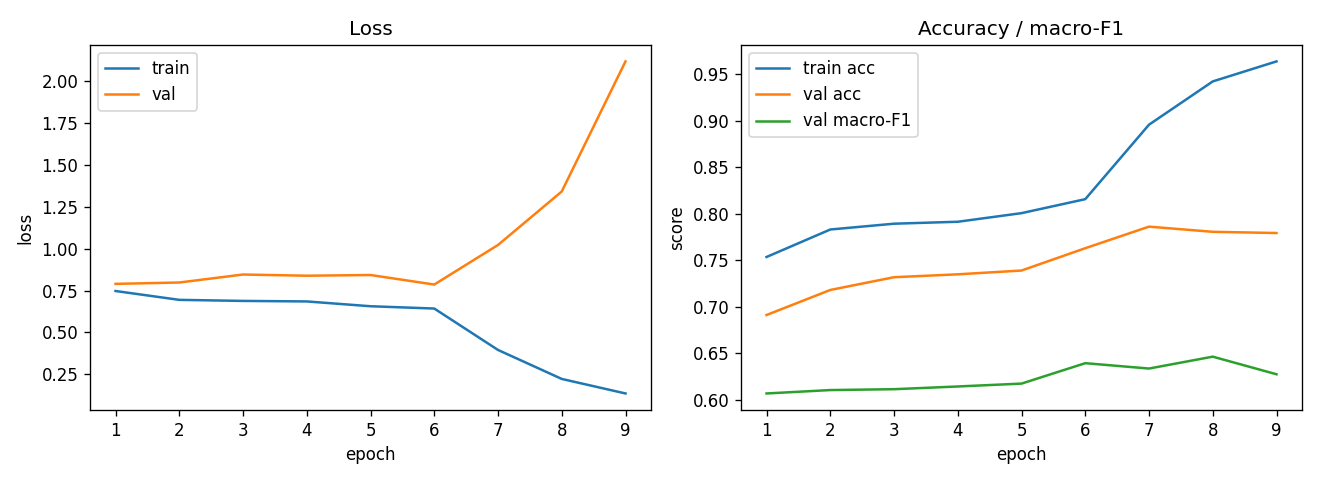

In [2]:
vm, tm = rec["val_metrics"], rec["test_metrics"]
print("VAL  acc={:.4f}  macro-F1={:.4f}  mild F1={:.4f} rec={:.4f}".format(
    vm["accuracy"], vm["macro_f1"], vm["per_class"]["mild"]["f1"], vm["per_class"]["mild"]["recall"]))
print("TEST acc={:.4f}  macro-F1={:.4f}".format(tm["accuracy"], tm["macro_f1"]))
print(json.dumps(vm["per_class"], indent=2))
curve = Path(rec["curves"])
display(Image(filename=str(curve))) if curve.exists() else print("missing", curve)
